<h1>Implement logistic regression model, apply sigmoid function, decision boundary. Apply regularization methods (Ridge and Lasso). 

Why Social_Network_Ads.csv?

Binary target: Purchased is 0 or 1, and logistic regression predicts a probability between 0 and 1 for a yes/no outcome. <br>Salary_Data.csv has a continuous target, so it doesn’t fit.
<br>Two numeric features: Age and EstimatedSalary can be plotted on a 2D chart, so the decision boundary is easy to draw and read.
<br>Clean and balanced enough: it has 400 rows, no missing values, and both classes are well represented.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

df = pd.read_csv("D:\BDA 20\BDA LAB\AIML-BDA-Lab-Work\AssignmentFiles\data\Social_Network_Ads.csv")

print(df.shape)
print(df.head())
print(df.describe())
print(df.isnull().sum())
print(df["Purchased"].value_counts())


(400, 5)
    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.581524e+07   60.000000    150000.000000    1.000000
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
Purcha

In [4]:
x = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=45)

sc_x = StandardScaler()
x_train = sc_x.fit_transform(x_train)
x_test = sc_x.transform(x_test)

Same as sklearn's probabilities: True
Accuracy: 0.8375
Confusion matrix:
 [[45  3]
 [10 22]]


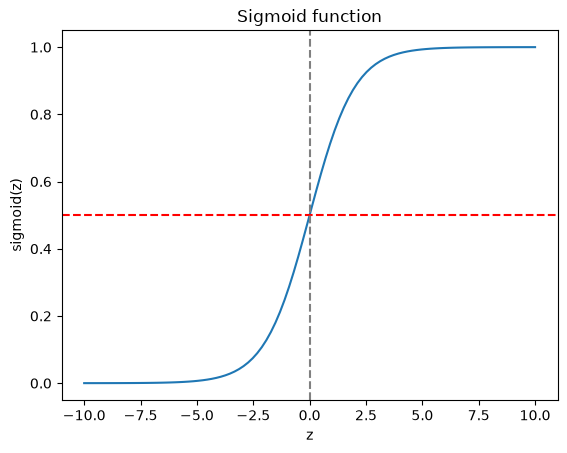

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

model = LogisticRegression()
model.fit(x_train, y_train)

# Manual calculation: z = b + w1*Age + w2*Salary, then probability = sigmoid(z)
z = model.intercept_ + x_test @ model.coef_.T
prob = sigmoid(z).ravel()
pred = (prob >= 0.5).astype(int)

print("Same as sklearn's probabilities:", np.allclose(prob, model.predict_proba(x_test)[:, 1]))
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))

# Plot the sigmoid curve
z_vals = np.linspace(-10, 10, 100)
plt.plot(z_vals, sigmoid(z_vals))
plt.axhline(0.5, color="red", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.title("Sigmoid function")
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.show()

Decision boundary: -1.100 + 2.089*Age + 1.088*Salary = 0  (scaled features)


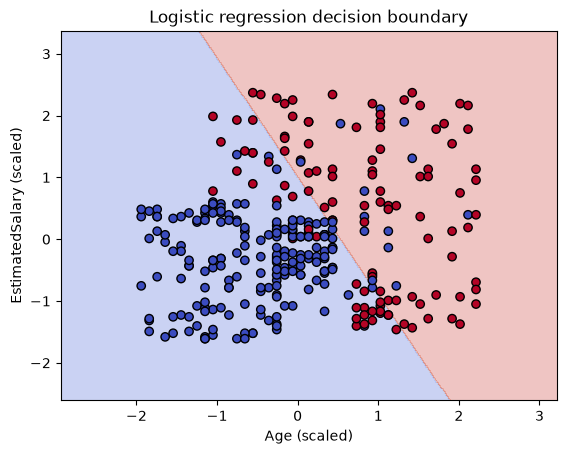

In [6]:
w1, w2 = model.coef_[0]
b = model.intercept_[0]
print(f"Decision boundary: {b:.3f} + {w1:.3f}*Age + {w2:.3f}*Salary = 0  (scaled features)")

# Grid of points covering the plot area
x1_min, x1_max = x_train[:, 0].min() - 1, x_train[:, 0].max() + 1
x2_min, x2_max = x_train[:, 1].min() - 1, x_train[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))

zz = model.predict(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

plt.contourf(xx1, xx2, zz, alpha=0.3, cmap="coolwarm")
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap="coolwarm", edgecolor="k")
plt.title("Logistic regression decision boundary")
plt.xlabel("Age (scaled)")
plt.ylabel("EstimatedSalary (scaled)")
plt.show()

In [7]:
import pandas as pd

rows = []
for C in [0.01, 0.1, 1, 10]:          # C = 1/lambda, so a smaller C means a stronger penalty
    for name, penalty in [("Ridge (L2)", "l2"), ("Lasso (L1)", "l1")]:
        m = LogisticRegression(penalty=penalty, C=C, solver="liblinear")
        m.fit(x_train, y_train)
        rows.append({
            "Penalty": name,
            "C": C,
            "Age coef": m.coef_[0][0],
            "Salary coef": m.coef_[0][1],
            "Train acc": m.score(x_train, y_train),
            "Test acc": m.score(x_test, y_test),
        })

print(pd.DataFrame(rows).round(4))

      Penalty      C  Age coef  Salary coef  Train acc  Test acc
0  Ridge (L2)   0.01    0.5083       0.2900     0.8438    0.8375
1  Lasso (L1)   0.01    0.0000       0.0000     0.6531    0.6000
2  Ridge (L2)   0.10    1.3746       0.7315     0.8469    0.8375
3  Lasso (L1)   0.10    1.4695       0.6869     0.8562    0.8500
4  Ridge (L2)   1.00    2.0700       1.0800     0.8438    0.8375
5  Lasso (L1)   1.00    2.1484       1.1081     0.8406    0.8375
6  Ridge (L2)  10.00    2.2503       1.1703     0.8406    0.8375
7  Lasso (L1)  10.00    2.2608       1.1745     0.8406    0.8375


c:\Users\bda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\bda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\U